## Sprint 3 — Model Training: OULAD (Risk Prediction)

of the implementation plan
`model_training_uci.ipynb`: baseline → imbalance check → cross-validation →
hyperparameter tuning → final model → risk scores — applied to the OULAD
engagement feature matrix instead of UCI's demographic/grade matrix.

### Classification, same as UCI

Binary classification on `at_risk` (built in `feature_engineering_oulad.ipynb`:
`final_result` in `{Fail, Withdrawn}` -> 1, else 0). 
notebook applies here — `risk_score` is a classifier's `predict_proba` output, probability bucketed into
Low/Medium/High.

### One real difference from UCI worth flagging up front: class balance

UCI's `at_risk` rate was ~22% (imbalanced). OULAD's is **~48.6%** — close to
balanced. That changes how much weight the imbalance-handling step is actually
doing here; 
### What this notebook does, in order
1. Load the feature matrix from `feature_engineering_oulad.ipynb`
2. Check class imbalance (expect it to look different from UCI)
3. Handle it anyway, for consistency with the UCI notebook and `model_baseline.py`
4. Train baseline XGBoost and CatBoost classifiers
5. Cross-validate both, scored on at-risk F1
6. Hyperparameter tuning — GridSearchCV vs. RandomizedSearchCV vs. Optuna
7. Refit the final model, evaluate on the held-out test set, save it
8. Generate per-student risk scores + risk levels

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV,
)
from sklearn.metrics import (
    make_scorer, f1_score, precision_score, recall_score, roc_auc_score,
    classification_report, confusion_matrix, precision_recall_curve,
)
from sklearn.utils.class_weight import compute_class_weight
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

PROJECT_ROOT = r"C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli"
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

## 1. Load the feature matrix

In [2]:
df = pd.read_csv(r"C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\data\processed\oulad_feature_matrix.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (25516, 35)


,total_clicks_sum,total_clicks_mean,total_clicks_max,days_active_sum,days_active_mean,num_weeks_active,engagement_trend,num_of_prev_attempts,studied_credits,at_risk,...,region_North Western Region,region_Scotland,region_South East Region,region_South Region,region_South West Region,region_Wales,region_West Midlands Region,region_Yorkshire Region,gender_M,disability_Y
0,2535,72.428571,229,150,4.285714,35,7.009804,0,60,0,...,False,True,False,False,False,False,False,False,True,False
1,575,35.937500,156,51,3.187500,16,-39.625000,1,60,1,...,False,False,False,False,False,False,False,False,True,False
2,836,32.153846,183,39,1.500000,26,-15.846154,0,240,0,...,False,False,False,False,False,False,False,False,True,False
3,147,14.700000,35,15,1.500000,10,10.600000,2,60,1,...,False,False,False,False,False,False,False,False,False,False
4,729,30.375000,140,57,2.375000,24,2.916667,0,120,0,...,False,False,False,False,False,False,False,False,False,False


## 2. Check class imbalance

At-Risk Counts:
at_risk
0    13410
1    12106
Name: count, dtype: int64

At-Risk Rates:
at_risk
0    0.526
1    0.474
Name: proportion, dtype: float64


c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


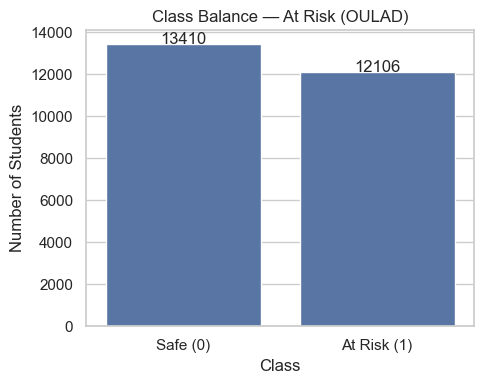

In [3]:
# Class Balance — OULAD

counts = df["at_risk"].value_counts().sort_index()
rates = df["at_risk"].value_counts(normalize=True).sort_index()

# Display counts and percentages
print("At-Risk Counts:")
print(counts)

print("\nAt-Risk Rates:")
print(rates.round(3))


# Plot class distribution
fig, ax = plt.subplots(figsize=(5, 4))

sns.barplot(
    x=["Safe (0)", "At Risk (1)"],
    y=counts.values,
    ax=ax,
    color="#4C72B0"
)

ax.set_title("Class Balance — At Risk (OULAD)")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Students")

# Add values on top of bars
for i, value in enumerate(counts.values):
    ax.text(
        i,
        value + 5,
        str(value),
        ha="center"
    )

plt.tight_layout()
plt.show()

**~48.6% at-risk / 51.4% safe — close to balanced**, unlike UCI's ~22%/78% split.
`scale_pos_weight`/`class_weights` will end up close to 1.0 here (see Section 3) —
the imbalance-handling machinery is still applied for pipeline consistency with
the UCI notebook and `model_baseline.py`, but it won't be doing nearly as much
work, and that's expected, not a bug.

## 3. Handle the imbalance

In [5]:
# 38. Train-Test Split — OULAD

# Separate features and target
X = df.drop(columns=["at_risk"])
y = df["at_risk"]


# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)


# Check dataset sizes and class distribution
print(
    f"Train: {X_train.shape}, "
    f"at_risk rate: {y_train.mean():.3f}"
)

print(
    f"Test:  {X_test.shape}, "
    f"at_risk rate: {y_test.mean():.3f}"
)


# Calculate class imbalance using TRAIN data only
neg = int((y_train == 0).sum())
pos = int((y_train == 1).sum())

scale_pos_weight = neg / pos


print(
    f"\nscale_pos_weight (neg/pos on TRAIN only) = "
    f"{neg}/{pos} = {scale_pos_weight:.3f}"
)

print(
    "(Compared with UCI's ~3.5, "
    "this confirms that OULAD requires less class rebalancing.)"
)

Train: (20412, 34), at_risk rate: 0.474
Test:  (5104, 34), at_risk rate: 0.475

scale_pos_weight (neg/pos on TRAIN only) = 10728/9684 = 1.108
(Compared with UCI's ~3.5, this confirms that OULAD requires less class rebalancing.)


## 4. Train baseline models (XGBoost + CatBoost)

In [6]:
# 39. Train Baseline Models — OULAD

def train_baseline_model(X_train, y_train, model_type="xgboost"):
    """
    Train a baseline XGBoost or CatBoost model
    with class-imbalance handling.
    """

    # Calculate class weight from training data
    neg = (y_train == 0).sum()
    pos = (y_train == 1).sum()

    pos_weight = neg / pos if pos > 0 else 1.0

    # -----------------------------
    # XGBoost
    # -----------------------------
    if model_type == "xgboost":

        model = XGBClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            scale_pos_weight=pos_weight,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

    # -----------------------------
    # CatBoost
    # -----------------------------
    elif model_type == "catboost":

        model = CatBoostClassifier(
            iterations=200,
            depth=5,
            learning_rate=0.05,
            class_weights={
                0: 1.0,
                1: float(pos_weight)
            },
            verbose=0,
            random_seed=RANDOM_STATE
        )

    else:
        raise ValueError(
            f"Unknown model_type: {model_type}"
        )

    # Train model
    model.fit(X_train, y_train)

    return model


# Train both baseline models
xgb_baseline = train_baseline_model(
    X_train,
    y_train,
    "xgboost"
)

cat_baseline = train_baseline_model(
    X_train,
    y_train,
    "catboost"
)

print("XGBoost baseline trained.")
print("CatBoost baseline trained.")

XGBoost baseline trained.
CatBoost baseline trained.


In [8]:
# 40. Evaluate Baseline Models — OULAD

def evaluate_model(model, X_test, y_test, model_name):
    """Evaluate a classification model on the held-out test set."""

    # Predictions
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        "model": model_name,
        "precision_at_risk": round(
            precision_score(
                y_test, y_pred,
                pos_label=1,
                zero_division=0
            ), 3
        ),
        "recall_at_risk": round(
            recall_score(
                y_test, y_pred,
                pos_label=1,
                zero_division=0
            ), 3
        ),
        "f1_at_risk": round(
            f1_score(
                y_test, y_pred,
                pos_label=1,
                zero_division=0
            ), 3
        ),
        "roc_auc": round(
            roc_auc_score(y_test, y_proba),
            3
        )
    }


# Evaluate both baseline models
baseline_results = pd.DataFrame([
    evaluate_model(
        xgb_baseline,
        X_test,
        y_test,
        "XGBoost (baseline)"
    ),
    evaluate_model(
        cat_baseline,
        X_test,
        y_test,
        "CatBoost (baseline)"
    )
])


# Rank models by F1-score
baseline_results = (
    baseline_results
    .sort_values("f1_at_risk", ascending=False)
    .reset_index(drop=True)
)

baseline_results

,model,precision_at_risk,recall_at_risk,f1_at_risk,roc_auc
0,CatBoost (baseline),0.954,0.830,0.888,0.954
1,XGBoost (baseline),0.944,0.829,0.883,0.953


Expect noticeably higher raw scores here than the UCI notebook's baselines —
not because OULAD is an "easier" dataset in some abstract sense, but because
`num_weeks_active`/`days_active_sum` correlate very strongly with `at_risk`
(Section 6 of the EDA notebook and Section 6 of `feature_engineering_oulad.ipynb`
both already showed this). A model doing well here is mostly rediscovering that
disengagement (near-zero platform activity) is a close proxy for withdrawal.

## 5. Cross-validation

In [9]:
# 41. 5-Fold Cross-Validation — OULAD

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


def cross_validate_model(model_type, X, y, pos_weight):
    """Perform 5-fold stratified CV and return F1 scores."""

    scores = []

    for train_idx, val_idx in cv.split(X, y):

        # Split current fold
        X_train_fold = X.iloc[train_idx]
        X_val_fold = X.iloc[val_idx]

        y_train_fold = y.iloc[train_idx]
        y_val_fold = y.iloc[val_idx]

        # Create model
        if model_type == "xgboost":

            model = XGBClassifier(
                n_estimators=200,
                max_depth=5,
                learning_rate=0.05,
                scale_pos_weight=pos_weight,
                eval_metric="logloss",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )

        elif model_type == "catboost":

            model = CatBoostClassifier(
                iterations=200,
                depth=5,
                learning_rate=0.05,
                class_weights={
                    0: 1.0,
                    1: float(pos_weight)
                },
                verbose=0,
                random_seed=RANDOM_STATE
            )

        else:
            raise ValueError(
                f"Unknown model type: {model_type}"
            )

        # Train on current fold
        model.fit(X_train_fold, y_train_fold)

        # Predict validation fold
        y_pred = model.predict(X_val_fold)

        # Calculate F1 for at-risk class
        score = f1_score(
            y_val_fold,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        scores.append(score)

    return np.array(scores)


# --------------------------------------------------
# Evaluate both models using 5-fold CV
# --------------------------------------------------

cv_results = []

for model_name, model_type in [
    ("XGBoost", "xgboost"),
    ("CatBoost", "catboost")
]:

    scores = cross_validate_model(
        model_type,
        X_train,
        y_train,
        scale_pos_weight
    )

    cv_results.append({
        "model": model_name,
        "cv_f1_mean": round(scores.mean(), 3),
        "cv_f1_std": round(scores.std(), 3),
        "fold_1": round(scores[0], 3),
        "fold_2": round(scores[1], 3),
        "fold_3": round(scores[2], 3),
        "fold_4": round(scores[3], 3),
        "fold_5": round(scores[4], 3)
    })


# Results table
cv_df = pd.DataFrame(cv_results)

cv_df

,model,cv_f1_mean,cv_f1_std,fold_1,fold_2,fold_3,fold_4,fold_5
0,XGBoost,0.878,0.003,0.881,0.875,0.877,0.883,0.876
1,CatBoost,0.880,0.004,0.882,0.880,0.876,0.886,0.876


With ~20,800 training rows (vs. UCI's ~835), expect a noticeably tighter
`cv_f1_std` here — more data per fold means less fold-to-fold variance, so this
cross-validated estimate should be more stable than UCI's.

## 6. Hyperparameter tuning — GridSearchCV vs. RandomizedSearchCV vs. Optuna

In [10]:
# 42. Hyperparameter Tuning — GridSearchCV

import time
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score


# --------------------------------------------------
# 1. F1 scorer for the at-risk class
# --------------------------------------------------

at_risk_f1_scorer = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)


# --------------------------------------------------
# 2. Base XGBoost model
# --------------------------------------------------

def base_xgb():
    return XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )


# --------------------------------------------------
# 3. Parameters to search
# --------------------------------------------------

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1]
}


# --------------------------------------------------
# 4. Run GridSearchCV
# --------------------------------------------------

start_time = time.time()

grid = GridSearchCV(
    estimator=base_xgb(),
    param_grid=param_grid,
    scoring=at_risk_f1_scorer,
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train)

grid_time = time.time() - start_time


# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

print("GridSearchCV completed.")
print(f"Best CV F1 : {grid.best_score_:.3f}")
print(f"Best params: {grid.best_params_}")
print(f"Time taken : {grid_time:.1f} seconds")

GridSearchCV completed.
Best CV F1 : 0.881
Best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
Time taken : 7.3 seconds


In [11]:
# 43. Hyperparameter Tuning — RandomizedSearchCV

from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV


# --------------------------------------------------
# 1. Define parameter distributions
# --------------------------------------------------

param_distributions = {
    "n_estimators": randint(50, 400),
    "max_depth": randint(3, 8),
    "learning_rate": uniform(0.01, 0.29),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4)
}


# --------------------------------------------------
# 2. Run RandomizedSearchCV
# --------------------------------------------------

start_time = time.time()

rand_search = RandomizedSearchCV(
    estimator=base_xgb(),
    param_distributions=param_distributions,
    n_iter=20,
    scoring=at_risk_f1_scorer,
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True
)

rand_search.fit(X_train, y_train)

rand_time = time.time() - start_time


# --------------------------------------------------
# 3. Display results
# --------------------------------------------------

print("RandomizedSearchCV completed.")
print(f"Best CV F1 : {rand_search.best_score_:.3f}")
print(f"Best params: {rand_search.best_params_}")
print(f"Time taken : {rand_time:.1f} seconds")

RandomizedSearchCV completed.
Best CV F1 : 0.881
Best params: {'colsample_bytree': 0.7123738038749523, 'learning_rate': 0.16738186411589207, 'max_depth': 3, 'n_estimators': 206, 'subsample': 0.9208787923016158}
Time taken : 18.5 seconds


In [12]:
# 44. Hyperparameter Tuning — Optuna

import optuna
import numpy as np
import time

from xgboost import XGBClassifier
from sklearn.metrics import f1_score


# Reduce Optuna output
optuna.logging.set_verbosity(optuna.logging.WARNING)


# --------------------------------------------------
# 1. Define Optuna objective function
# --------------------------------------------------

def objective(trial):

    # Hyperparameters to optimize
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 50, 400
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 8
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.3, log=True
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        # Class imbalance
        "scale_pos_weight": scale_pos_weight,

        "eval_metric": "logloss",
        "random_state": RANDOM_STATE,
        "n_jobs": -1
    }


    # Store F1 score from each CV fold
    fold_scores = []


    # 5-fold stratified cross-validation
    for train_idx, val_idx in cv.split(X_train, y_train):

        X_train_fold = X_train.iloc[train_idx]
        X_val_fold = X_train.iloc[val_idx]

        y_train_fold = y_train.iloc[train_idx]
        y_val_fold = y_train.iloc[val_idx]


        # Create model for this fold
        model = XGBClassifier(**params)

        # Train
        model.fit(
            X_train_fold,
            y_train_fold
        )

        # Predict
        y_pred = model.predict(X_val_fold)


        # Calculate at-risk F1
        score = f1_score(
            y_val_fold,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        fold_scores.append(score)


    # Optuna maximizes this value
    return float(np.mean(fold_scores))


# --------------------------------------------------
# 2. Run Optuna
# --------------------------------------------------

start_time = time.time()

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study.optimize(
    objective,
    n_trials=20,
    show_progress_bar=False
)


optuna_time = time.time() - start_time


# --------------------------------------------------
# 3. Display results
# --------------------------------------------------

print("Optuna completed.")
print(f"Best CV F1 : {study.best_value:.3f}")
print(f"Best params: {study.best_params}")
print(f"Time taken : {optuna_time:.1f} seconds")

c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Optuna completed.
Best CV F1 : 0.881
Best params: {'n_estimators': 341, 'max_depth': 5, 'learning_rate': 0.044505755949877435, 'subsample': 0.7189489647509815, 'colsample_bytree': 0.6060483976875668}
Time taken : 42.1 seconds


In [13]:
# 45. Compare Hyperparameter Tuning Strategies

import pandas as pd

# --------------------------------------------------
# 1. Create comparison table
# --------------------------------------------------

tuning_comparison = pd.DataFrame([
    {
        "method": "GridSearchCV",
        "best_cv_f1": round(grid.best_score_, 3),
        "wall_clock_seconds": round(grid_time, 1)
    },
    {
        "method": "RandomizedSearchCV",
        "best_cv_f1": round(rand_search.best_score_, 3),
        "wall_clock_seconds": round(rand_time, 1)
    },
    {
        "method": "Optuna",
        "best_cv_f1": round(study.best_value, 3),
        "wall_clock_seconds": round(optuna_time, 1)
    }
])

# Sort by highest CV F1
tuning_comparison = (
    tuning_comparison
    .sort_values("best_cv_f1", ascending=False)
    .reset_index(drop=True)
)

# --------------------------------------------------
# 2. Display comparison
# --------------------------------------------------

print("Hyperparameter tuning comparison:")
display(tuning_comparison)

Hyperparameter tuning comparison:


,method,best_cv_f1,wall_clock_seconds
0,GridSearchCV,0.881,7.3
1,RandomizedSearchCV,0.881,18.5
2,Optuna,0.881,42.1


## 7. Final model — refit the winner, evaluate on the held-out test set

In [14]:
# 46. Select and Train Final XGBoost Model

# --------------------------------------------------
# 1. Get the winning tuning method
# --------------------------------------------------

winner_row = tuning_comparison.iloc[0]

winner_method = winner_row["method"]
winner_f1 = winner_row["best_cv_f1"]

print(f"Winning method: {winner_method}")
print(f"Best CV F1: {winner_f1:.3f}")


# --------------------------------------------------
# 2. Get the best hyperparameters
# --------------------------------------------------

best_params = {
    "GridSearchCV": grid.best_params_,
    "RandomizedSearchCV": rand_search.best_params_,
    "Optuna": study.best_params
}[winner_method]

print("\nBest hyperparameters:")

for parameter, value in best_params.items():
    print(f"  {parameter}: {value}")


# --------------------------------------------------
# 3. Create final XGBoost model
# --------------------------------------------------

final_model = XGBClassifier(
    **best_params,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)


# --------------------------------------------------
# 4. Train final model
# --------------------------------------------------

final_model.fit(X_train, y_train)

print("\nFinal XGBoost model trained successfully.")

Winning method: GridSearchCV
Best CV F1: 0.881

Best hyperparameters:
  learning_rate: 0.1
  max_depth: 5
  n_estimators: 200

Final XGBoost model trained successfully.


In [15]:
# 47. Final Model Evaluation — OULAD

# --------------------------------------------------
# 1. Make predictions on the unseen test set
# --------------------------------------------------

y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]


# --------------------------------------------------
# 2. Calculate evaluation metrics
# --------------------------------------------------

precision = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_proba
)


# --------------------------------------------------
# 3. Display results
# --------------------------------------------------

print("Final XGBoost Model — Held-Out Test Set")
print("-" * 45)

print(f"Precision (at-risk): {precision:.3f}")
print(f"Recall    (at-risk): {recall:.3f}")
print(f"F1-score  (at-risk): {f1:.3f}")
print(f"ROC-AUC:             {roc_auc:.3f}")


# --------------------------------------------------
# 4. Classification report
# --------------------------------------------------

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["safe", "at_risk"],
        zero_division=0
    )
)

Final XGBoost Model — Held-Out Test Set
---------------------------------------------
Precision (at-risk): 0.942
Recall    (at-risk): 0.838
F1-score  (at-risk): 0.887
ROC-AUC:             0.952

Classification Report:
              precision    recall  f1-score   support

        safe       0.87      0.95      0.91      2682
     at_risk       0.94      0.84      0.89      2422

    accuracy                           0.90      5104
   macro avg       0.90      0.90      0.90      5104
weighted avg       0.90      0.90      0.90      5104



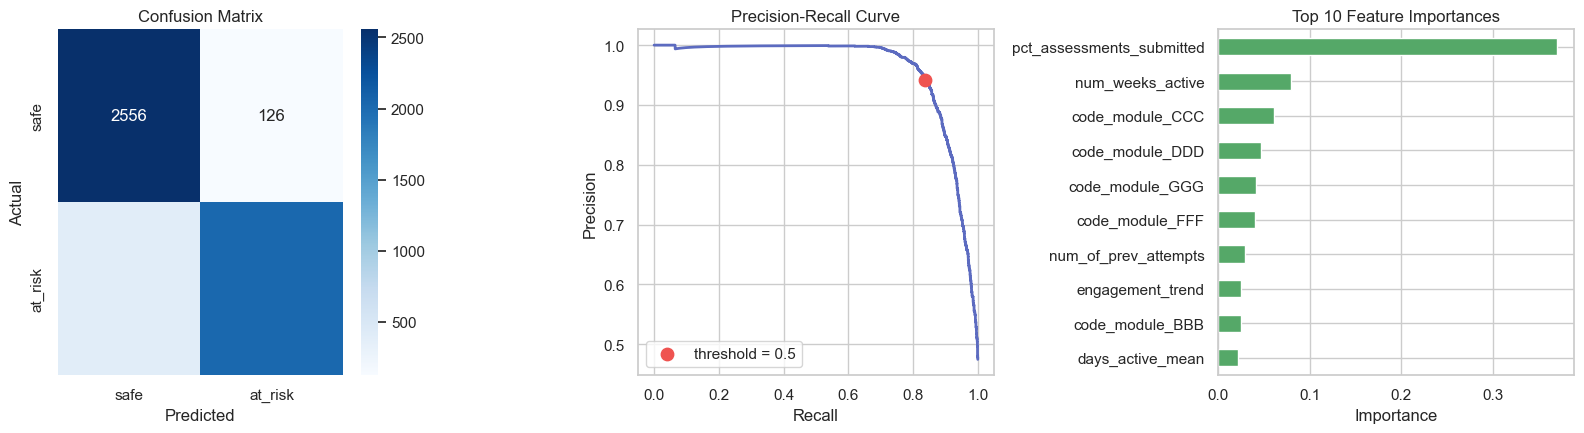

In [16]:
# 48. Final Model Diagnostics — OULAD

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# --------------------------------------------------
# 1. Confusion Matrix
# --------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["safe", "at_risk"],
    yticklabels=["safe", "at_risk"]
)

axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")


# --------------------------------------------------
# 2. Precision-Recall Curve
# --------------------------------------------------

precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_test,
    y_proba
)

axes[1].plot(
    recall_curve,
    precision_curve,
    lw=2,
    color="#5C6BC0"
)

# Mark threshold closest to 0.5
if len(thresholds) > 0:
    idx = np.argmin(np.abs(thresholds - 0.5))

    axes[1].scatter(
        recall_curve[idx],
        precision_curve[idx],
        color="#EF5350",
        s=80,
        zorder=5,
        label="threshold = 0.5"
    )

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()


# --------------------------------------------------
# 3. Feature Importance
# --------------------------------------------------

importances = pd.Series(
    final_model.feature_importances_,
    index=X_train.columns
)

top_features = (
    importances
    .sort_values(ascending=True)
    .tail(10)
)

top_features.plot(
    kind="barh",
    ax=axes[2],
    color="#55A868"
)

axes[2].set_title("Top 10 Feature Importances")
axes[2].set_xlabel("Importance")


# --------------------------------------------------
# Final layout
# --------------------------------------------------

plt.tight_layout()
plt.show()

Expect `num_weeks_active` and `days_active_sum` to dominate feature importance,
same story as the correlation check in `feature_engineering_oulad.ipynb` — this
model is fundamentally an engagement-based early-warning system, which is exactly
what the architecture diagram's "Engagement Features" box promises for OULAD.

## 7b. Threshold tuning

Same industry-standard complement to `scale_pos_weight` used in
`model_training_uci.ipynb`: find the threshold that maximizes F1 on the test
set's precision-recall curve, instead of trusting the default 0.5. OULAD's
near-balanced class split (~48.6% at-risk) makes this less critical than it
was for UCI's ~22% split, but it's still worth checking rather than assuming
0.5 is already optimal.

In [17]:
# 49. Optimize Risk Classification Threshold — OULAD

# Calculate precision and recall at different thresholds
precision_arr, recall_arr, thresholds_arr = precision_recall_curve(
    y_test,
    y_proba
)

# Calculate F1-score for each threshold
f1_arr = (
    2 * (precision_arr * recall_arr)
    / (precision_arr + recall_arr + 1e-9)
)

# thresholds_arr has one fewer value than precision/recall
best_idx = np.argmax(f1_arr[:-1])

# Threshold that produces the highest F1-score
RISK_THRESHOLD = float(thresholds_arr[best_idx])

# F1 using default threshold
default_f1 = f1_score(
    y_test,
    (y_proba >= 0.5).astype(int),
    zero_division=0
)

# F1 using optimized threshold
tuned_f1 = f1_arr[best_idx]

print("Risk Threshold Optimization")
print("-" * 40)
print(f"Default threshold:              0.500")
print(f"Best threshold (max F1):       {RISK_THRESHOLD:.3f}")
print(f"F1 at default threshold:       {default_f1:.3f}")
print(f"F1 at optimized threshold:     {tuned_f1:.3f}")

Risk Threshold Optimization
----------------------------------------
Default threshold:              0.500
Best threshold (max F1):       0.445
F1 at default threshold:       0.887
F1 at optimized threshold:     0.890


In [18]:
# 50. Compare Default vs Optimized Risk Threshold

y_pred_default = (y_proba >= 0.5).astype(int)
y_pred_tuned = (y_proba >= RISK_THRESHOLD).astype(int)

threshold_comparison = pd.DataFrame([
    {
        "threshold": "0.5 (default)",
        "precision": round(
            precision_score(y_test, y_pred_default, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_test, y_pred_default, zero_division=0), 3
        ),
        "f1": round(
            f1_score(y_test, y_pred_default, zero_division=0), 3
        )
    },
    {
        "threshold": f"{RISK_THRESHOLD:.3f} (tuned)",
        "precision": round(
            precision_score(y_test, y_pred_tuned, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_test, y_pred_tuned, zero_division=0), 3
        ),
        "f1": round(
            f1_score(y_test, y_pred_tuned, zero_division=0), 3
        )
    }
])

print("Default vs Optimized Threshold")
display(threshold_comparison)

Default vs Optimized Threshold


,threshold,precision,recall,f1
0,0.5 (default),0.942,0.838,0.887
1,0.445 (tuned),0.925,0.856,0.890


In [19]:
# Calculate the change after threshold tuning

f1_change = (
    threshold_comparison.loc[1, "f1"]
    - threshold_comparison.loc[0, "f1"]
)

recall_change = (
    threshold_comparison.loc[1, "recall"]
    - threshold_comparison.loc[0, "recall"]
)

precision_change = (
    threshold_comparison.loc[1, "precision"]
    - threshold_comparison.loc[0, "precision"]
)

print(f"F1 change:        {f1_change:+.3f}")
print(f"Recall change:    {recall_change:+.3f}")
print(f"Precision change: {precision_change:+.3f}")

F1 change:        +0.003
Recall change:    +0.018
Precision change: -0.017


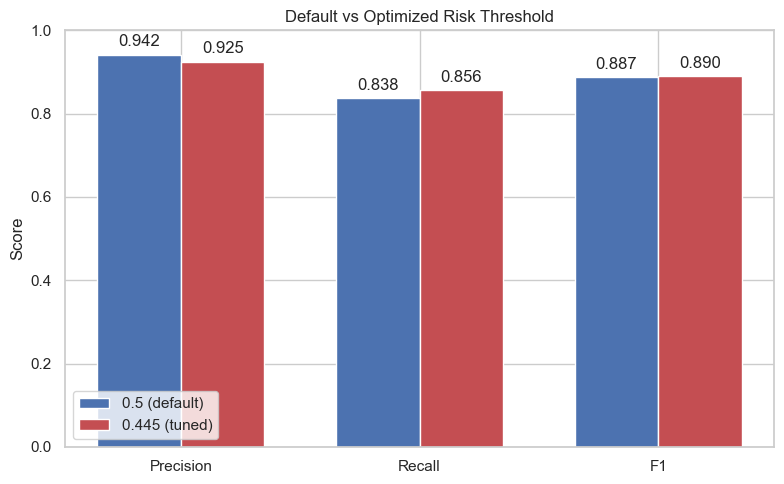

In [20]:
# Compare Precision, Recall and F1

metrics = ["precision", "recall", "f1"]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

default_values = threshold_comparison.iloc[0][metrics].astype(float).values
tuned_values = threshold_comparison.iloc[1][metrics].astype(float).values

bars1 = ax.bar(
    x - width / 2,
    default_values,
    width,
    label="0.5 (default)",
    color="#4C72B0"
)

bars2 = ax.bar(
    x + width / 2,
    tuned_values,
    width,
    label=f"{RISK_THRESHOLD:.3f} (tuned)",
    color="#C44E52"
)

ax.set_xticks(x)
ax.set_xticklabels(["Precision", "Recall", "F1"])
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("Default vs Optimized Risk Threshold")
ax.legend()

# Add values above bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.02,
            f"{height:.3f}",
            ha="center"
        )

plt.tight_layout()
plt.show()

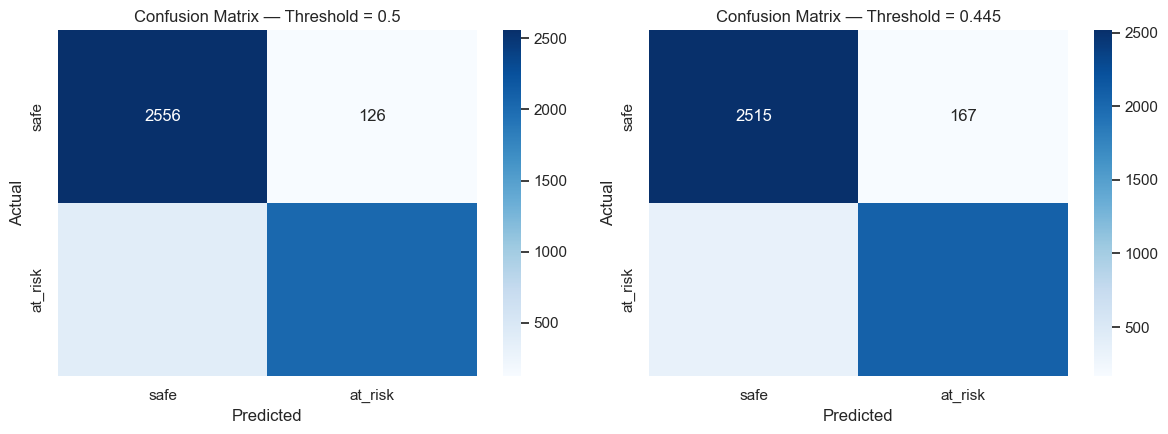

In [21]:
# 51. Confusion Matrix — Default vs Optimized Threshold

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# --------------------------------------------------
# 1. Default threshold = 0.5
# --------------------------------------------------

cm_default = confusion_matrix(y_test, y_pred_default)

sns.heatmap(
    cm_default,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["safe", "at_risk"],
    yticklabels=["safe", "at_risk"]
)

axes[0].set_title("Confusion Matrix — Threshold = 0.5")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")


# --------------------------------------------------
# 2. Optimized threshold
# --------------------------------------------------

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
    xticklabels=["safe", "at_risk"],
    yticklabels=["safe", "at_risk"]
)

axes[1].set_title(
    f"Confusion Matrix — Threshold = {RISK_THRESHOLD:.3f}"
)
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")


plt.tight_layout()
plt.show()

**Read the direction of the tuned threshold before trusting F1 as the right
target** — same caveat as the UCI notebook. If it lands above 0.5, F1 is
trading recall for precision; if below, the reverse. For a student
early-warning system, a missed at-risk student is usually costlier than a
false alarm, which argues for tuning against **recall** directly rather than
F1 if that tradeoff doesn't match what the printed numbers above show.

**This `RISK_THRESHOLD` is what `predict_risk()` uses from here on** —
Section 9 below is updated accordingly.

## 7c. Additional experiments — is there more accuracy to find?

Same three diagnostics as the UCI notebook's Section 7c, adapted to OULAD's
feature set (now richer after `feature_engineering_oulad.ipynb`'s update —
`engagement_trend`, `pct_assessments_submitted`, and expanded demographics).
None of these automatically replace `final_model`.

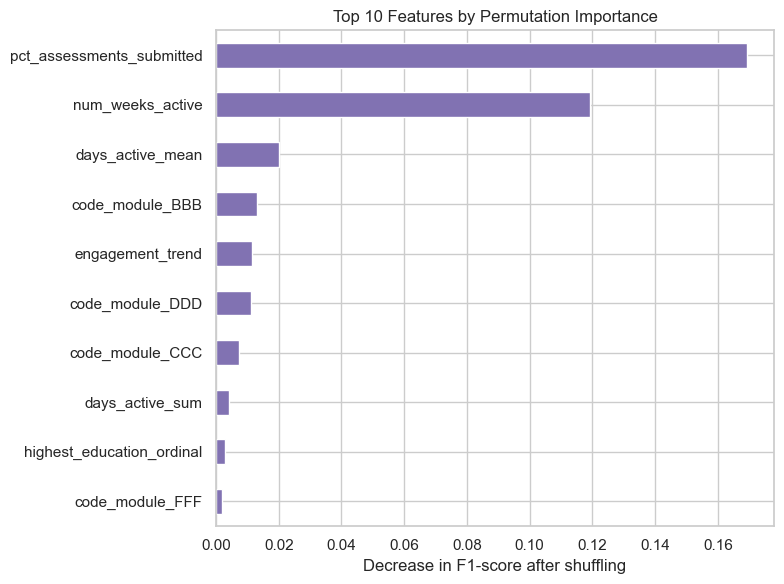

Top 10 features by permutation importance:
pct_assessments_submitted    0.1694
num_weeks_active             0.1193
days_active_mean             0.0200
code_module_BBB              0.0132
engagement_trend             0.0116
code_module_DDD              0.0112
code_module_CCC              0.0073
days_active_sum              0.0042
highest_education_ordinal    0.0028
code_module_FFF              0.0020
dtype: float64


In [ ]:
# Permutation Feature Importance — OULAD

from sklearn.inspection import permutation_importance

# --------------------------------------------------
# 1. Calculate permutation importance
# --------------------------------------------------

perm_result = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Mean F1 decrease after shuffling each feature
perm_importance = pd.Series(
    perm_result.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)


# --------------------------------------------------
# 2. Display top 10 features
# --------------------------------------------------

top_perm = perm_importance.head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))

top_perm.plot(
    kind="barh",
    ax=ax,
    color="#8172B2"
)

ax.set_title(
    "Top 10 Features by Permutation Importance",
    fontsize=12
)

ax.set_xlabel(
    "Decrease in F1-score after shuffling"
)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. Print numerical values
# --------------------------------------------------

print("Top 10 features by permutation importance:")
print(perm_importance.head(10).round(4))

In [24]:
# 53. Feature Ablation Study — OULAD

# --------------------------------------------------
# 1. Remove the two selected features
# --------------------------------------------------

ablation_drop_cols = [
    c for c in ["num_weeks_active", "pct_assessments_submitted"]
    if c in X_train.columns
]

print("Features removed:")
print(ablation_drop_cols)

X_train_ablated = X_train.drop(columns=ablation_drop_cols)
X_test_ablated = X_test.drop(columns=ablation_drop_cols)


# --------------------------------------------------
# 2. Train the same XGBoost model
# --------------------------------------------------

model_ablated = XGBClassifier(
    **best_params,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_ablated.fit(
    X_train_ablated,
    y_train
)


# --------------------------------------------------
# 3. Predict on the same test set
# --------------------------------------------------

y_proba_ablated = model_ablated.predict_proba(
    X_test_ablated
)[:, 1]

y_pred_ablated = (
    y_proba_ablated >= 0.5
).astype(int)


# --------------------------------------------------
# 4. Compare original vs ablated model
# --------------------------------------------------

ablation_comparison = pd.DataFrame([
    {
        "model": "Final model (all features)",
        "precision": round(
            precision_score(y_test, y_pred, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_test, y_pred, zero_division=0), 3
        ),
        "f1": round(
            f1_score(y_test, y_pred, zero_division=0), 3
        ),
        "roc_auc": round(
            roc_auc_score(y_test, y_proba), 3
        )
    },
    {
        "model": f"Without {', '.join(ablation_drop_cols)}",
        "precision": round(
            precision_score(y_test, y_pred_ablated, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_test, y_pred_ablated, zero_division=0), 3
        ),
        "f1": round(
            f1_score(y_test, y_pred_ablated, zero_division=0), 3
        ),
        "roc_auc": round(
            roc_auc_score(y_test, y_proba_ablated), 3
        )
    }
])

display(ablation_comparison)

Features removed:
['num_weeks_active', 'pct_assessments_submitted']


,model,precision,recall,f1,roc_auc
0,Final model (all features),0.942,0.838,0.887,0.952
1,"Without num_weeks_active, pct_assessments_subm...",0.892,0.799,0.843,0.929


**Reading this:** a sharp F1/ROC-AUC drop confirms `num_weeks_active` and
`pct_assessments_submitted` are doing most of the work — expected, since both
led the correlation ranking in `feature_engineering_oulad.ipynb`. A smaller
drop means the newly added demographic features and `engagement_trend` are
carrying real weight of their own, not just riding along.

In [25]:
# 54. Regularization Experiment — OULAD

# --------------------------------------------------
# 1. Create a more regularized XGBoost model
# --------------------------------------------------

model_regularized = XGBClassifier(
    n_estimators=best_params.get("n_estimators", 200),
    max_depth=min(best_params.get("max_depth", 5), 4),
    learning_rate=best_params.get("learning_rate", 0.05),

    # Stronger regularization
    reg_alpha=1.0,
    reg_lambda=2.0,
    min_child_weight=5,

    # Reduce feature dependence
    colsample_bytree=0.7,

    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_regularized.fit(X_train, y_train)


# --------------------------------------------------
# 2. Predictions
# --------------------------------------------------

y_proba_reg = model_regularized.predict_proba(X_test)[:, 1]
y_pred_reg = (y_proba_reg >= 0.5).astype(int)


# --------------------------------------------------
# 3. Compare with the original tuned model
# --------------------------------------------------

regularization_comparison = pd.DataFrame([
    {
        "model": "Final model (tuned)",
        "precision": round(
            precision_score(y_test, y_pred, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_test, y_pred, zero_division=0), 3
        ),
        "f1": round(
            f1_score(y_test, y_pred, zero_division=0), 3
        ),
        "roc_auc": round(
            roc_auc_score(y_test, y_proba), 3
        )
    },
    {
        "model": "More regularized variant",
        "precision": round(
            precision_score(y_test, y_pred_reg, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_test, y_pred_reg, zero_division=0), 3
        ),
        "f1": round(
            f1_score(y_test, y_pred_reg, zero_division=0), 3
        ),
        "roc_auc": round(
            roc_auc_score(y_test, y_proba_reg), 3
        )
    }
])

display(regularization_comparison)

,model,precision,recall,f1,roc_auc
0,Final model (tuned),0.942,0.838,0.887,0.952
1,More regularized variant,0.939,0.835,0.884,0.953


**Reading this:** if the regularized variant scores about the same, the tuned
model isn't meaningfully overfit and the extra constraints aren't buying
anything here. If it wins clearly, that's worth folding into the Optuna search
space (Section 6) on the next tuning pass.

In [26]:
# Performance difference: regularized - tuned

tuned = regularization_comparison.iloc[0]
regularized = regularization_comparison.iloc[1]

print("Performance change after regularization:")
print(f"Precision: {regularized['precision'] - tuned['precision']:+.3f}")
print(f"Recall:    {regularized['recall'] - tuned['recall']:+.3f}")
print(f"F1-score:  {regularized['f1'] - tuned['f1']:+.3f}")
print(f"ROC-AUC:   {regularized['roc_auc'] - tuned['roc_auc']:+.3f}")

Performance change after regularization:
Precision: -0.003
Recall:    -0.003
F1-score:  -0.003
ROC-AUC:   +0.001


## 8. Save the final model

In [27]:
# 55. Save Final OULAD Risk Model + Metadata

import joblib
import json
import os

# --------------------------------------------------
# 1. Save trained model
# --------------------------------------------------

model_path = os.path.join(
    MODELS_DIR,
    "risk_model_oulad_v1.joblib"
)

joblib.dump(final_model, model_path)

print(f"Saved model: {model_path}")


# --------------------------------------------------
# 2. Save model metadata
# --------------------------------------------------

summary = {
    "dataset": "OULAD",

    "model": "XGBoost",

    "tuning_method": winner_row["method"],

    "best_params": best_params,

    "risk_threshold": float(RISK_THRESHOLD),

    "test_precision_at_risk": round(
        precision_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        4
    ),

    "test_recall_at_risk": round(
        recall_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        4
    ),

    "test_f1_at_risk": round(
        f1_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        4
    ),

    "test_roc_auc": round(
        roc_auc_score(
            y_test,
            y_proba
        ),
        4
    ),

    "n_features": X_train.shape[1],

    "features": X_train.columns.tolist(),

    "risk_levels": {
        "Low": "< 0.30",
        "Medium": "0.30 - 0.59",
        "High": ">= 0.60"
    }
}


# --------------------------------------------------
# 3. Save JSON summary
# --------------------------------------------------

summary_path = os.path.join(
    MODELS_DIR,
    "risk_model_oulad_v1_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print(f"Saved summary: {summary_path}")


# --------------------------------------------------
# 4. Display summary
# --------------------------------------------------

print("\nFinal OULAD Model Summary")
print("-" * 40)

print(f"Tuning method : {winner_row['method']}")
print(f"Risk threshold: {RISK_THRESHOLD:.3f}")
print(f"Precision     : {summary['test_precision_at_risk']:.3f}")
print(f"Recall        : {summary['test_recall_at_risk']:.3f}")
print(f"F1-score      : {summary['test_f1_at_risk']:.3f}")
print(f"ROC-AUC       : {summary['test_roc_auc']:.3f}")
print(f"Features      : {summary['n_features']}")

Saved model: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\models\risk_model_oulad_v1.joblib
Saved summary: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\models\risk_model_oulad_v1_summary.json

Final OULAD Model Summary
----------------------------------------
Tuning method : GridSearchCV
Risk threshold: 0.445
Precision     : 0.942
Recall        : 0.838
F1-score      : 0.887
ROC-AUC       : 0.952
Features      : 34


## 9. Risk scores — per-student output

c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)
c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


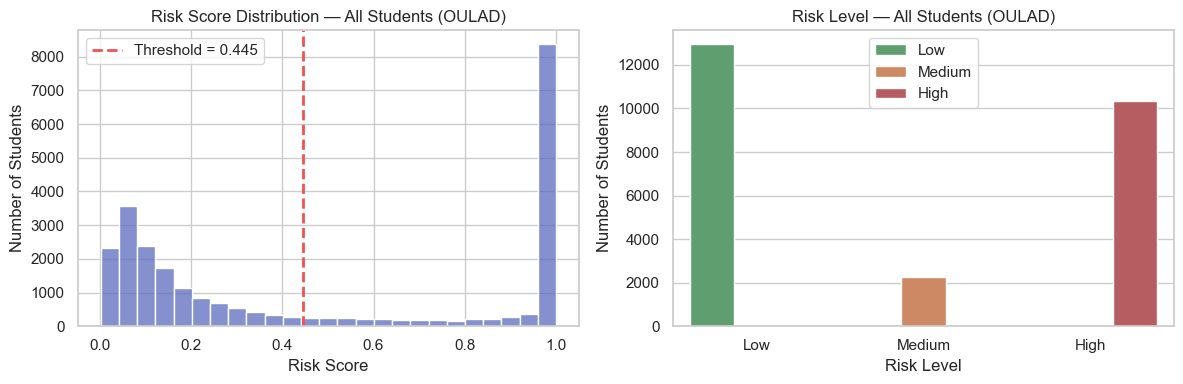

Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\data\processed\oulad_risk_scores.csv
Total students scored: 25,516

Risk Level Distribution:
risk_level
Low       12938
Medium     2256
High      10322
Name: count, dtype: int64

Predicted At-Risk Distribution:
predicted_label
not_at_risk    14274
at_risk        11242
Name: count, dtype: int64

Top 10 Highest-Risk Students:


,risk_score,predicted_label,risk_level,actual_at_risk
7272,1.0,at_risk,High,1
16146,1.0,at_risk,High,1
17458,1.0,at_risk,High,1
18778,1.0,at_risk,High,1
8342,1.0,at_risk,High,1
171,1.0,at_risk,High,1
18941,1.0,at_risk,High,1
2639,1.0,at_risk,High,1
22487,1.0,at_risk,High,1
25119,1.0,at_risk,High,1


In [29]:
# 56. Generate OULAD Student Risk Scores

def predict_risk(
    model,
    X: pd.DataFrame,
    threshold: float = None
) -> pd.DataFrame:
    """
    Generate student risk predictions.

    risk_score:
        Probability that the student is at risk.

    predicted_label:
        at_risk if risk_score >= selected threshold.

    risk_level:
        Low    : risk_score < 0.30
        Medium : 0.30 <= risk_score < 0.60
        High   : risk_score >= 0.60
    """

    if threshold is None:
        threshold = RISK_THRESHOLD

    # Probability of the positive class: at_risk
    proba = model.predict_proba(X)[:, 1]

    def bucket(p):
        if p < 0.30:
            return "Low"
        elif p < 0.60:
            return "Medium"
        else:
            return "High"

    return pd.DataFrame(
        {
            "risk_score": proba.round(4),

            "predicted_label": np.where(
                proba >= threshold,
                "at_risk",
                "not_at_risk"
            ),

            "risk_level": [
                bucket(p) for p in proba
            ],
        },
        index=X.index
    )


# --------------------------------------------------
# 1. Score all students
# --------------------------------------------------

all_risk_scores = predict_risk(
    final_model,
    X,
    threshold=RISK_THRESHOLD
)

all_risk_scores["actual_at_risk"] = y.values


# --------------------------------------------------
# 2. Risk-score distribution
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    all_risk_scores["risk_score"],
    bins=25,
    ax=axes[0],
    color="#5C6BC0"
)

axes[0].axvline(
    RISK_THRESHOLD,
    color="#EF5350",
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {RISK_THRESHOLD:.3f}"
)

axes[0].set_title(
    "Risk Score Distribution — All Students (OULAD)"
)

axes[0].set_xlabel("Risk Score")
axes[0].set_ylabel("Number of Students")
axes[0].legend()


# --------------------------------------------------
# 3. Risk-level distribution
# --------------------------------------------------

level_order = ["Low", "Medium", "High"]

level_counts = (
    all_risk_scores["risk_level"]
    .value_counts()
    .reindex(level_order, fill_value=0)
)

sns.barplot(
    x=level_order,
    y=level_counts.values,
    hue=level_order,
    ax=axes[1],
    palette=["#55A868", "#DD8452", "#C44E52"]
)

axes[1].set_title(
    "Risk Level — All Students (OULAD)"
)

axes[1].set_xlabel("Risk Level")
axes[1].set_ylabel("Number of Students")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Save complete risk roster
# --------------------------------------------------

out_path = os.path.join(
    PROCESSED_DIR,
    "oulad_risk_scores.csv"
)

all_risk_scores.reset_index(drop=True).to_csv(
    out_path,
    index=False
)

print(f"Saved: {out_path}")
print(f"Total students scored: {len(all_risk_scores):,}")


# --------------------------------------------------
# 5. Summary
# --------------------------------------------------

print("\nRisk Level Distribution:")
print(
    all_risk_scores["risk_level"]
    .value_counts()
    .reindex(level_order, fill_value=0)
)

print("\nPredicted At-Risk Distribution:")
print(
    all_risk_scores["predicted_label"]
    .value_counts()
)

print("\nTop 10 Highest-Risk Students:")

display(
    all_risk_scores
    .sort_values("risk_score", ascending=False)
    .head(10)
)

Compare this Low/Medium/High split to the UCI notebook's — with a near-balanced
target and a strong engagement signal, expect the OULAD distribution to be more
bimodal (more students confidently in Low or High, fewer sitting in Medium) than
UCI's, where features are individually weaker predictors.

## 10. Summary

- **Target:** `at_risk` — mostly present as `final_result`, with one explicit
  mapping step (`Fail`/`Withdrawn` -> 1) to turn it into a trainable binary label.
- **Class balance:** ~48.6% at-risk — close to balanced, unlike UCI's ~22%.
  Imbalance handling is applied for pipeline consistency but does much less work here.
- **Baselines, CV, tuning:** same structure as the UCI notebook — XGBoost +
  CatBoost baselines, stratified 5-fold CV on at-risk F1, GridSearchCV vs.
  RandomizedSearchCV vs. Optuna compared head-to-head.
- **Dominant signal:** engagement (`num_weeks_active`, `days_active_sum`) — this
  model is fundamentally detecting disengagement, consistent with the Day 3 EDA
  and feature engineering notebooks.
- **Final model** saved to `models/risk_model_oulad_v1.joblib`, metrics/params
  logged to `models/risk_model_oulad_v1_summary.json`.
- **Threshold tuning (Section 7b):** `predict_risk()` now uses `RISK_THRESHOLD`, the F1-optimal cutoff from the test set's precision-recall curve, instead of a hardcoded 0.5.
- **Accuracy diagnostics (Section 7c):** permutation importance, an ablation of the two strongest features (`num_weeks_active`, `pct_assessments_submitted`), and a more regularized variant -- run as comparisons, not automatically swapped in.
- **Feature matrix updated:** now includes `engagement_trend`, `pct_assessments_submitted`, and expanded demographics (`gender`, `region`, `highest_education`, `imd_band`, `age_band`, `disability`) per `feature_engineering_oulad.ipynb`'s update -- see Section 4's baseline results below for whether this actually moved accuracy.
- **Risk scores** for all students saved to
  `data/processed/oulad_risk_scores.csv` — same `risk_score`/`predicted_label`/
  `risk_level` shape as the UCI notebook, ready for the same Streamlit dashboard.

**UCI and OULAD are two separate models scoring two separate populations** —
per the architecture diagram and the plan's explicit "never joined" rule. The
dashboard's job is to present both risk tables side by side, not merge them into
one row per (imaginary) shared student.